In [1]:
import matplotlib.pyplot as plt 
import numpy as np 
import xarray as xr 
import cartopy
import cmocean 
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
#NK 
nk_path = '/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/saved_nc'
nk_year = xr.open_dataset(f'{nk_path}/yearly_average.nc')
nk_month = xr.open_dataset(f'{nk_path}/monthly_average.nc')
#HB
from dataloader_inf import open_dataset
hb_path = '/lustre/storeB/project/fou/hi/foccus/malene/run-ocean-anemoi/ppi/external_checkpoint_inference/results/rollout_benchmark_lr3.5e6-rs3-i0-m3/step_51000_e14/resampled_means'
hb_year = open_dataset(f'{hb_path}/yearly_mean.nc').ds
hb_month = open_dataset(f'{hb_path}/monthly_mean.nc').ds

In [3]:
nk_temp = nk_year.temperature
hb_temp = hb_year.temperature

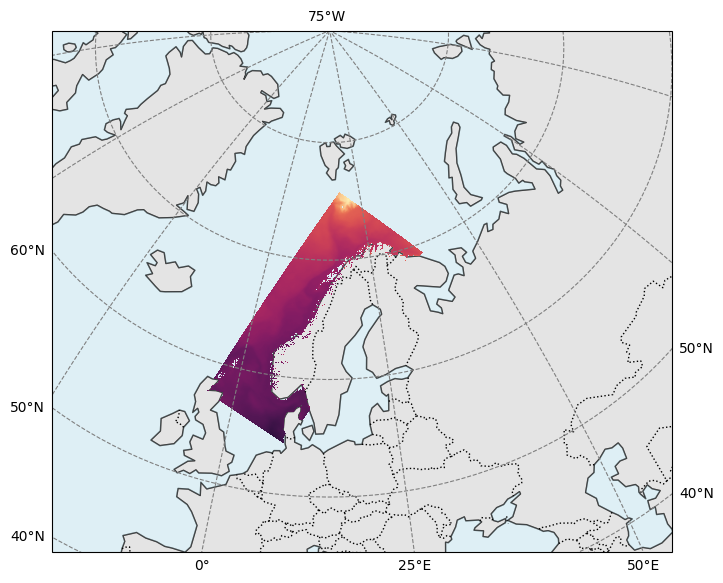

In [46]:
fig, ax = plt.subplots(1, figsize = (8,8), subplot_kw={'projection' : ccrs.Orthographic(central_latitude=65, central_longitude=15)})
ax.pcolormesh(nk_temp.lon, nk_temp.lat, nk_temp[0,:,:].values, transform=ccrs.PlateCarree(), cmap = cmocean.cm.matter)
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray', alpha =0.6)
ax.add_feature(cfeature.OCEAN, edgecolor = 'black', facecolor = 'lightblue', alpha = 0.4)
ax.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), color='gray', linestyle='--')
ax.add_feature(cfeature.BORDERS, linestyle = ':')
norway = [-20, 60, 45.0, 90.0]
ax.set_global()
ax.set_extent(norway, crs=ccrs.PlateCarree())